# CTA 'L' Analysis

## Code

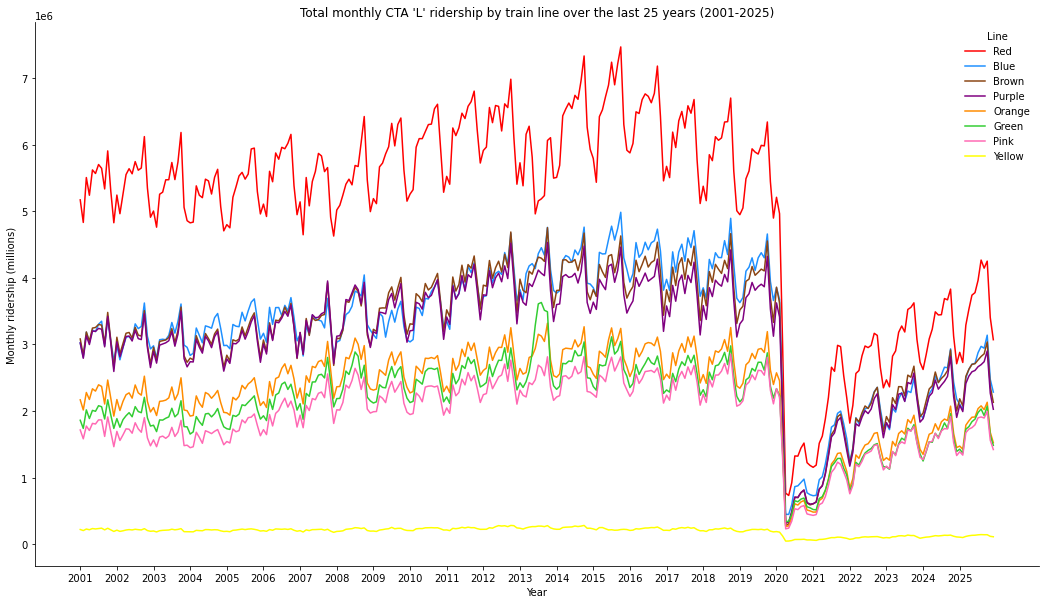

In [44]:
# Load libraries/packages

import pandas as pd
import matplotlib.pyplot as plt

# Load datasets

df_ridership = pd.read_csv('CTA_L_Ridership.csv')
df_stops = pd.read_csv('CTA_L_Stops.csv')

# Keep only columns needed for analysis and do some basic cleaning

df_ridership = df_ridership[['stationame', 'month_beginning', 'monthtotal']]
df_ridership = df_ridership.rename(columns={'stationame': 'STATION_NAME'})
df_ridership['month_beginning'] = pd.to_datetime(df_ridership['month_beginning'])
df_ridership = df_ridership[df_ridership['month_beginning'].dt.year < 2026]

df_stops = df_stops[['STATION_NAME', 'RED', 'BLUE', 'G', 'BRN', 'P', 'Y', 'Pnk', 'O']]
df_stops = df_stops.drop_duplicates()

# Mapping - df_ridership data changes

df_ridership = df_ridership[df_ridership['STATION_NAME']!='Homan']
df_ridership.loc[df_ridership['STATION_NAME']=="Harlem-O'Hare", 'STATION_NAME'] = 'Harlem-Forest Park'
df_ridership.loc[df_ridership['STATION_NAME']=='Western/Milwaukee', 'STATION_NAME'] = 'Western-Forest Park'
df_ridership.loc[df_ridership['STATION_NAME']=='Madison/Wabash', 'STATION_NAME'] = 'Washington/Wabash'
df_ridership.loc[df_ridership['STATION_NAME']=='Randolph/Wabash', 'STATION_NAME'] = 'Washington/Wabash'
df_ridership.loc[df_ridership['STATION_NAME']=='Skokie', 'STATION_NAME'] = 'Dempster-Skokie'
df_ridership.loc[df_ridership['STATION_NAME']=='Washington/State', 'STATION_NAME'] = 'Lake/State'
df_ridership.loc[df_ridership['STATION_NAME']=='35-Bronzeville-IIT', 'STATION_NAME'] = '35th-Bronzeville-IIT'

# Mapping - df_stops data changes - single train line

df_stops.loc[df_stops['STATION_NAME']=='63rd', 'STATION_NAME'] = '63rd-Dan Ryan'
df_stops.loc[df_stops['STATION_NAME']=='Division', 'STATION_NAME'] = 'Division/Milwaukee'
df_stops.loc[df_stops['STATION_NAME']=='Cottage Grove', 'STATION_NAME'] = 'East 63rd-Cottage Grove'
df_stops.loc[df_stops['STATION_NAME']=='Harlem/Lake', 'STATION_NAME'] = 'Harlem-Lake'
df_stops.loc[df_stops['STATION_NAME']=='Harlem', 'STATION_NAME'] = 'Harlem-Forest Park'
df_stops.loc[df_stops['STATION_NAME']=='Harold Washington Library-State/Van Buren', 'STATION_NAME'] = 'Library'
df_stops.loc[df_stops['STATION_NAME']=='Illinois Medical District', 'STATION_NAME'] = 'Medical Center'
df_stops.loc[df_stops['STATION_NAME']=='Kedzie-Homan', 'STATION_NAME'] = 'Kedzie-Homan-Forest Park'
df_stops.loc[df_stops['STATION_NAME']=='Lake', 'STATION_NAME'] = 'Lake/State'
df_stops.loc[df_stops['STATION_NAME']=='Midway', 'STATION_NAME'] = 'Midway Airport'
df_stops.loc[df_stops['STATION_NAME']=='Morgan', 'STATION_NAME'] = 'Morgan-Lake'
df_stops.loc[df_stops['STATION_NAME']=="O'Hare", 'STATION_NAME'] = "O'Hare Airport"
df_stops.loc[df_stops['STATION_NAME']=='Sox-35th', 'STATION_NAME'] = 'Sox-35th-Dan Ryan'

# Mapping - df_stops data changes - multiple train lines

df_stops.loc[(df_stops['STATION_NAME']=='47th')&(df_stops['RED']==True), 'STATION_NAME'] = '47th-Dan Ryan'
df_stops.loc[(df_stops['STATION_NAME']=='47th')&(df_stops['G']==True), 'STATION_NAME'] = '47th-South Elevated'
df_stops.loc[(df_stops['STATION_NAME']=='Addison')&(df_stops['BRN']==True), 'STATION_NAME'] = 'Addison-Brown'
df_stops.loc[(df_stops['STATION_NAME']=='Addison')&(df_stops['RED']==True), 'STATION_NAME'] = 'Addison-North Main'
df_stops.loc[(df_stops['STATION_NAME']=='Addison')&(df_stops['BLUE']==True), 'STATION_NAME'] = "Addison-O'Hare"
df_stops.loc[(df_stops['STATION_NAME']=='Ashland')&(df_stops['G']==True)&(df_stops['Pnk']==True), 'STATION_NAME'] = 'Ashland-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Ashland')&(df_stops['O']==True), 'STATION_NAME'] = 'Ashland-Orange'
df_stops.loc[(df_stops['STATION_NAME']=='Austin')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Austin-Forest Park'
df_stops.loc[(df_stops['STATION_NAME']=='Austin')&(df_stops['G']==True), 'STATION_NAME'] = 'Austin-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Belmont')&(df_stops['BRN']==True)&(df_stops['P']==True), 'STATION_NAME'] = 'Belmont-North Main'
df_stops.loc[(df_stops['STATION_NAME']=='Belmont')&(df_stops['RED']==True), 'STATION_NAME'] = 'Belmont-North Main'
df_stops.loc[(df_stops['STATION_NAME']=='Belmont')&(df_stops['BLUE']==True), 'STATION_NAME'] = "Belmont-O'Hare"
df_stops.loc[(df_stops['STATION_NAME']=='California')&(df_stops['Pnk']==True), 'STATION_NAME'] = 'California-Cermak'
df_stops.loc[(df_stops['STATION_NAME']=='California')&(df_stops['G']==True), 'STATION_NAME'] = 'California-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='California')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'California/Milwaukee'
df_stops.loc[(df_stops['STATION_NAME']=='Central')&(df_stops['P']==True), 'STATION_NAME'] = 'Central-Evanston'
df_stops.loc[(df_stops['STATION_NAME']=='Central')&(df_stops['G']==True), 'STATION_NAME'] = 'Central-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Chicago')&(df_stops['BRN']==True)&(df_stops['P']==True), 'STATION_NAME'] = 'Chicago/Franklin'
df_stops.loc[(df_stops['STATION_NAME']=='Chicago')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Chicago/Milwaukee'
df_stops.loc[(df_stops['STATION_NAME']=='Chicago')&(df_stops['RED']==True), 'STATION_NAME'] = 'Chicago/State'
df_stops.loc[(df_stops['STATION_NAME']=='Cicero')&(df_stops['Pnk']==True), 'STATION_NAME'] = 'Cicero-Cermak'
df_stops.loc[(df_stops['STATION_NAME']=='Cicero')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Cicero-Forest Park'
df_stops.loc[(df_stops['STATION_NAME']=='Cicero')&(df_stops['G']==True), 'STATION_NAME'] = 'Cicero-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Clinton')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Clinton-Forest Park'
df_stops.loc[(df_stops['STATION_NAME']=='Clinton')&(df_stops['G']==True)&(df_stops['Pnk']==True), 'STATION_NAME'] = 'Clinton-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Damen')&(df_stops['BRN']==True), 'STATION_NAME'] = 'Damen-Brown'
df_stops.loc[(df_stops['STATION_NAME']=='Damen')&(df_stops['Pnk']==True), 'STATION_NAME'] = 'Damen-Cermak'
df_stops.loc[(df_stops['STATION_NAME']=='Damen')&(df_stops['G']==True), 'STATION_NAME'] = 'Damen-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Damen')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Damen/Milwaukee'
df_stops.loc[(df_stops['STATION_NAME']=='Garfield')&(df_stops['RED']==True), 'STATION_NAME'] = 'Garfield-Dan Ryan'
df_stops.loc[(df_stops['STATION_NAME']=='Garfield')&(df_stops['G']==True), 'STATION_NAME'] = 'Garfield-South Elevated'
df_stops.loc[(df_stops['STATION_NAME']=='Grand')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Grand/Milwaukee'
df_stops.loc[(df_stops['STATION_NAME']=='Grand')&(df_stops['RED']==True), 'STATION_NAME'] = 'Grand/State'
df_stops.loc[(df_stops['STATION_NAME']=='Halsted')&(df_stops['O']==True), 'STATION_NAME'] = 'Halsted-Orange'
df_stops.loc[(df_stops['STATION_NAME']=='Halsted')&(df_stops['G']==True), 'STATION_NAME'] = 'Halsted/63rd'
df_stops.loc[(df_stops['STATION_NAME']=='Irving Park')&(df_stops['BRN']==True), 'STATION_NAME'] = 'Irving Park-Brown'
df_stops.loc[(df_stops['STATION_NAME']=='Irving Park')&(df_stops['BLUE']==True), 'STATION_NAME'] = "Irving Park-O'Hare"
df_stops.loc[(df_stops['STATION_NAME']=='Jackson')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Jackson/Dearborn'
df_stops.loc[(df_stops['STATION_NAME']=='Jackson')&(df_stops['RED']==True), 'STATION_NAME'] = 'Jackson/State'
df_stops.loc[(df_stops['STATION_NAME']=='Kedzie')&(df_stops['BRN']==True), 'STATION_NAME'] = 'Kedzie-Brown'
df_stops.loc[(df_stops['STATION_NAME']=='Kedzie')&(df_stops['Pnk']==True), 'STATION_NAME'] = 'Kedzie-Cermak'
df_stops.loc[(df_stops['STATION_NAME']=='Kedzie')&(df_stops['G']==True), 'STATION_NAME'] = 'Kedzie-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Kedzie')&(df_stops['O']==True), 'STATION_NAME'] = 'Kedzie-Midway'
df_stops.loc[(df_stops['STATION_NAME']=='Monroe')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Monroe/Dearborn'
df_stops.loc[(df_stops['STATION_NAME']=='Monroe')&(df_stops['RED']==True), 'STATION_NAME'] = 'Monroe/State'
df_stops.loc[(df_stops['STATION_NAME']=='Montrose')&(df_stops['BRN']==True), 'STATION_NAME'] = 'Montrose-Brown'
df_stops.loc[(df_stops['STATION_NAME']=='Montrose')&(df_stops['BLUE']==True), 'STATION_NAME'] = "Montrose-O'Hare"
df_stops.loc[(df_stops['STATION_NAME']=='Oak Park')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Oak Park-Forest Park'
df_stops.loc[(df_stops['STATION_NAME']=='Oak Park')&(df_stops['G']==True), 'STATION_NAME'] = 'Oak Park-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Pulaski')&(df_stops['Pnk']==True), 'STATION_NAME'] = 'Pulaski-Cermak'
df_stops.loc[(df_stops['STATION_NAME']=='Pulaski')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Pulaski-Forest Park'
df_stops.loc[(df_stops['STATION_NAME']=='Pulaski')&(df_stops['G']==True), 'STATION_NAME'] = 'Pulaski-Lake'
df_stops.loc[(df_stops['STATION_NAME']=='Pulaski')&(df_stops['O']==True), 'STATION_NAME'] = 'Pulaski-Orange'
df_stops.loc[(df_stops['STATION_NAME']=='Washington')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Washington/Dearborn'
df_stops.loc[(df_stops['STATION_NAME']=='Western')&(df_stops['BRN']==True), 'STATION_NAME'] = 'Western-Brown'
df_stops.loc[(df_stops['STATION_NAME']=='Western')&(df_stops['Pnk']==True), 'STATION_NAME'] = 'Western-Cermak'
df_stops.loc[(df_stops['STATION_NAME']=='Western')&(df_stops['BLUE']==True), 'STATION_NAME'] = 'Western-Forest Park'
df_stops.loc[(df_stops['STATION_NAME']=='Western')&(df_stops['O']==True), 'STATION_NAME'] = 'Western-Orange'

# Merge df_ridership and df_stops

df_merge = pd.merge(df_ridership, df_stops, how='left', on='STATION_NAME')
df_merge['month_beginning'] = df_merge['month_beginning'].dt.to_period('M')
df_merge['monthtotal'] = df_merge['monthtotal'].str.replace(',','').astype(int)

# Save copy of df_merge for each line

df_red = df_merge[df_merge['RED']==True]
df_red = df_red[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_red = df_red.drop_duplicates()

df_blue = df_merge[df_merge['BLUE']==True]
df_blue = df_blue[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_blue = df_blue.drop_duplicates()

df_green = df_merge[df_merge['G']==True]
df_green = df_green[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_green = df_green.drop_duplicates()

df_brown = df_merge[df_merge['BRN']==True]
df_brown = df_brown[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_brown = df_brown.drop_duplicates()

df_purple = df_merge[df_merge['P']==True]
df_purple = df_purple[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_purple = df_purple.drop_duplicates()

df_yellow = df_merge[df_merge['Y']==True]
df_yellow = df_yellow[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_yellow = df_yellow.drop_duplicates()

df_pink = df_merge[df_merge['Pnk']==True]
df_pink = df_pink[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_pink = df_pink.drop_duplicates()

df_orange = df_merge[df_merge['O']==True]
df_orange = df_orange[['month_beginning', 'STATION_NAME', 'monthtotal']]
df_orange = df_orange.drop_duplicates()

# For each line df, group by month and sum month total

df_red_group = df_red.groupby(by=df_red['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})
df_blue_group = df_blue.groupby(by=df_blue['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})
df_green_group = df_green.groupby(by=df_green['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})
df_brown_group = df_brown.groupby(by=df_brown['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})
df_purple_group = df_purple.groupby(by=df_purple['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})
df_yellow_group = df_yellow.groupby(by=df_yellow['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})
df_pink_group = df_pink.groupby(by=df_pink['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})
df_orange_group = df_orange.groupby(by=df_orange['month_beginning'], as_index=False).agg({'monthtotal': 'sum'})

# Plot each line's monthly ridership data over the last 25 years
year_index = df_red_group.index[df_red_group['month_beginning'].dt.month==1].tolist()
year_value = df_red_group['month_beginning'].dt.year.unique().tolist()

plt.figure(figsize=(18, 10))
plt.gca().spines[['top', 'right']].set_visible(False)
plt.plot(df_red_group['monthtotal'], c='red', label='Red');
plt.plot(df_blue_group['monthtotal'], c='dodgerblue', label='Blue');
plt.plot(df_brown_group['monthtotal'], c='saddlebrown', label='Brown');
plt.plot(df_purple_group['monthtotal'], c='purple', label='Purple');
plt.plot(df_orange_group['monthtotal'], c='darkorange', label='Orange');
plt.plot(df_green_group['monthtotal'], c='limegreen', label='Green');
plt.plot(df_pink_group['monthtotal'], c='hotpink', label='Pink');
plt.plot(df_yellow_group['monthtotal'], c='yellow', label='Yellow');
plt.xticks(ticks=year_index, labels=year_value);
plt.xlabel('Year');
plt.ylabel('Monthly ridership (millions)');
plt.title("Total monthly CTA 'L' ridership by train line over the last 25 years (2001-2025)");
plt.legend(frameon=False, title='Line');

## Questions

### State the region and the domain category that your data sets are about (e.g., Chaohu, China and sports or athletics).
Chicago, Illinois, United States 
and public transportation (trains)

### Create a research question about the domain category and region that you identified.
How has total monthly CTA 'L' ridership by train line (e.g., red, blue, etc.) changed over the last 25 years (2001-2025)?

### Provide at least two links to publicly accessible datasets. These could be links to files such as CSV or Excel files, or links to websites which might have data in tabular form, such as Wikipedia pages.
https://data.cityofchicago.org/Transportation/CTA-Ridership-L-Station-Entries-Monthly-Day-Type-A/t2rn-p8d7/about_data
https://data.cityofchicago.org/Transportation/CTA-System-Information-List-of-L-Stops/8pix-ypme/about_data

### Provide a short (1-2 paragraphs) justification of how your visual addresses your research question.
My visual was created to address my research question of how monthly CTA 'L' ridership by train line has changed over the last 25 years, from 2001-2025. To start, I pulled 2 datasets from the City of Chicago's data portal website. The first dataset contains monthly ridership data per 'L' train station from January 2001 through June 2026, but I dropped 2026 data to have 25 full years of data for the purpose of my analysis. The second dataset contains information on each 'L' stop. I used the second dataset to map each station in the first dataset to each train line in the second dataset. There was a lot of manual data manipulation required in both datasets to get the station names to match between the 2 datasets for a proper merge. After merging the 2 datasets, I made 1 unique dataframe for each 'L' line (8 total), and then I grouped each by year-month and summed the total monthly rider counts. Finally, I plotted all 8 lines' data on the same axes to show and compare monthly ridership trends over 25 years for each train line.

My visual indicates that over the last 25 years, it seems that there are 4 distinct groups of lines - the red line has the highest ridership, followed by blue/brown/purple, then by orange/green/pink, then by yellow with the lowest ridership. Ridership appeared to increase slightly for all 8 lines from 2001 through 2019, until all lines had an extremely sharp drop in ridership in 2020 due to COVID-19. Since 2020, ridership seems to have increased each year, but it has not come close to recovering to pre-pandemic levels. In addition to yearly trends, there appear to be monthly trends. For each train line, ridership seems to start lower in earlier months, increase throughout the year, then decline fairly steeply in later months. This cyclical pattern holds true both pre- and post-pandemic.

### As this assignment is for the whole course, you must incorporate and defend the principles discussed in the first week, specifically, Cairo’s principles of truth, beauty, function, and insight. For each of the following prompts, please provide a response that links each principle to one or more elements of your visual. Describe your design choices for your visual in regards to Cairo's principles of truthfulness, beauty, functionality, and insightfulness.
In regards to Cairo's principle of truthfulness, I was aware of my actions when cleaning, summarizing, and manipulating my data to ensure I did not mislead myself or my audience. For example, the y-axis of my plot starts at 0 and has tick marks at consistent intervals of 1 million, which helps the viewer understand the true magnitude of ridership. The x-axis of my plot also starts at the beginning of the data (2001) and has tick marks for each year, helping the reader understand how the data relates to time. I used x- and y-axis labels that are factual, not opinionated. I also made sure to use a neutral title for my plot to avoid swaying my audience towards my own conclusions.

Regarding beauty, I tried to keep my plot on the simpler side, keeping in mind Tufte's principle of minimizing chart junk. For example, I only kept 2 of the x- and y-axis spines on the plot (for the tick marks), I reduced the number of axis tick marks, and I tried to eliminate redundant information. I also used a simple white background with black text so that I could save color for emphasis. I think the beauty of my plot is that for each of the 8 lines, I chose the color corresponding most closely to each train line's name (e.g., the blue train line's data is colored blue on the plot). My strategic use of color helps the audience associate the data with each train line and more easily distinguish between the lines.

In regards to functionality, I believe my choice of 8 line plots on the same axes was the most functional choice to address my research question. I plotted year (with monthly data between the tick marks) along the x-axis to show that this is monthly time series data over the last 25 years, and I plotted total monthly ridership in millions on the y-axis. Another type of plot like a histogram would not have made sense here, and a plot such as a bar chart would not have been as clean as a line graph. I plotted all 8 train lines on the same axes to help the viewer compare ridership by line. I gave each train line the color corresponding to its name, and the plot's legend confirms this. I made sure to use axis labels and a title for my plot to help the viewer better understand the data.

Regarding insightfulness, I believe all the elements of my visual allow the viewer to draw the same conclusions that I did. For example, with year being plotted on the x-axis, the audience is able to see the cyclical monthly patterns in ridership. With monthly ridership in millions on the y-axis, the reader can see how levels have changed over time, with subtle growth until a sharp drop in 2020 due to COVID-19, followed by faster growth post-pandemic, but not reaching pre-pandemic levels. By using colors that correspond to each train line's name, the viewer is more easily able to understand data associated with each train line, such as the 4 distinct groups of lines by ridership - red (highest), blue/brown/purple, orange/green/pink, and yellow (lowest). The presentation of data in my plot gives the audience insight into the answers to my research question.